In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os

os.environ["TQDM_DISABLE"] = "1"

# How far are these cells from the track?

`Trajectory.mindist` gives the distance from each point to a probe track. With `bounds` set to the insertion's entry and tip it measures to that segment; without it, to the infinite line through the probe. Coordinates are in metres from bregma, ordered ML, AP, DV.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from iblatlas.atlas import AllenAtlas, Insertion

ba = AllenAtlas()

# Stand-in insertion: entry in left cortex, 15° from vertical, tilted out of the coronal plane.
# from_dict takes micrometres; replace it with your own insertion.
ins = Insertion.from_dict({'x': -2243, 'y': -2000, 'z': 0, 'phi': 210, 'theta': 15, 'depth': 4000},
                          brain_atlas=ba)

# Stand-in cells: 2,000 points from the entry to past the tip, scattered around the track
rng = np.random.default_rng(0)
unit = (ins.tip - ins.entry) / np.linalg.norm(ins.tip - ins.entry)
along = rng.uniform(0, 1.15, 2000) * np.linalg.norm(ins.tip - ins.entry)
xyz = ins.entry + along[:, np.newaxis] * unit + rng.normal(0, 250e-6, (2000, 3))

In [3]:
distance_um = ins.trajectory.mindist(xyz, bounds=ins.xyz) * 1e6
distance_um[:5].round(1)

array([445.5, 305. , 297.4, 360.7, 245.8])

## The segment or the line

A point 500 µm past the tip, on the line of the probe, is 0 µm from the line and 500 µm from the segment:

In [4]:
past_tip = (ins.tip + 500e-6 * unit)[np.newaxis]  # mindist with bounds needs an (n, 3) array
print((ins.trajectory.mindist(past_tip) * 1e6).round(1))
print((ins.trajectory.mindist(past_tip, bounds=ins.xyz) * 1e6).round(1))

[0.]
[500.]


## Keep the cells near the probe

Select the cells within 100 µm of the track, for example to match them to the channels that recorded them:

In [5]:
near = distance_um < 100
print(f'{near.sum()} of {near.size} cells are within 100 µm of the track')

107 of 2000 cells are within 100 µm of the track


Plotted against depth along the track, from the entry, each cell's distance from the track shows which cells fall inside the 100 µm limit:

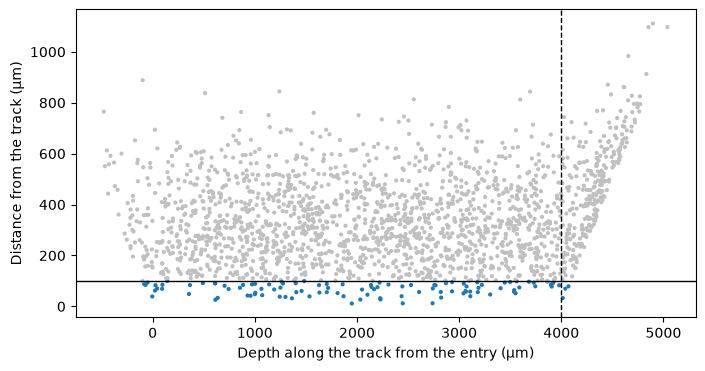

In [6]:
depth_um = (xyz - ins.entry) @ unit * 1e6

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(depth_um, distance_um, s=4, c=np.where(near, 'C0', 'silver'))
ax.axhline(100, color='k', lw=1)
ax.axvline(np.linalg.norm(ins.tip - ins.entry) * 1e6, color='k', ls='--', lw=1)  # tip
ax.set(xlabel='Depth along the track from the entry (µm)', ylabel='Distance from the track (µm)');

The dashed line marks the tip: beyond it, distance is measured to the tip itself. For the regions the track passes through, see [Describe a probe insertion and list the regions it crosses](work-with-probe-insertions.qmd).